<a href="https://colab.research.google.com/github/LexDomingues/Confusion_matrix/blob/main/Confusion_Matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

from keras.preprocessing import image
from keras.applications.imagenet_utils import preprocess_input
from keras.models import Sequential
from keras.models import Model
import os

In [12]:
caminho_modelo = '/content/drive/MyDrive/modelo_cats_dogs_transfer_learning.keras'

model_new = keras.models.load_model(caminho_modelo)

In [13]:
!echo "Downloading cats_vs_dogs images"

!mkdir "/content/PetImages"

!cp -r "/content/drive/MyDrive/dataset/PetImages/Cat" "/content/PetImages/"
!cp -r "/content/drive/MyDrive/dataset/PetImages/Dog" "/content/PetImages/"
print(os.listdir("/content/PetImages"))
root = "/content/PetImages"
print(os.listdir(root))

mkdir: cannot create directory ‘/content/PetImages’: File exists
['Cat', 'Dog']
['Cat', 'Dog']


In [14]:
bad_files_tf = []

for category in ["Cat", "Dog"]:
  folder = f"/content/PetImages/{category}"

  for filename in os.listdir(folder):
      path = os.path.join(folder, filename)

      try:
          data = tf.io.read_file(path)
          image = tf.io.decode_image(
              data,
              channels=3,
              expand_animations=False
          )

          _ = image.numpy()

      except Exception as e:
          bad_files_tf.append((path, str(e)))

print("Problematic files:", len(bad_files_tf))

for path, error in bad_files_tf:
  print(path)
  print("Error:", error)

Problematic files: 11
/content/PetImages/Cat/4351.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input size should match (header_size + row_size * abs_height) but they differ by 2 [Op:DecodeImage] name: 
/content/PetImages/Cat/666.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input is empty. [Op:DecodeImage] name: 
/content/PetImages/Cat/10404.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, JPEG XL, PNG, GIF, BMP, WebP required. [Op:DecodeImage] name: 
/content/PetImages/Cat/Thumbs.db
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, JPEG XL, PNG, GIF, BMP, WebP required. [Op:DecodeImage] name: 
/content/PetImages/Dog/11912.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:local

In [15]:
bad_files = [
   "/content/PetImages/Cat/666.jpg",
   "/content/PetImages/Dog/11702.jpg",
   "/content/PetImages/Cat/4351.jpg",
   "/content/PetImages/Cat/Thumbs.db",
   "/content/PetImages/Cat/10404.jpg",
   "/content/PetImages/Dog/11912.jpg",
   "/content/PetImages/Dog/2317.jpg",
   "/content/PetImages/Dog/Thumbs.db",
   "/content/PetImages/Dog/11233.jpg",
   "/content/PetImages/Dog/2494.jpg",
   "/content/PetImages/Dog/9500.jpg",
   "/content/PetImages/Cat/2606.jpg",
   "/content/PetImages/Dog/9215.jpg",
]

for path in bad_files:
 if os.path.exists(path):
     os.remove(path)
     print("Removido:", path)

Removido: /content/PetImages/Cat/666.jpg
Removido: /content/PetImages/Dog/11702.jpg
Removido: /content/PetImages/Cat/4351.jpg
Removido: /content/PetImages/Cat/Thumbs.db
Removido: /content/PetImages/Cat/10404.jpg
Removido: /content/PetImages/Dog/11912.jpg
Removido: /content/PetImages/Dog/2317.jpg
Removido: /content/PetImages/Dog/Thumbs.db
Removido: /content/PetImages/Dog/11233.jpg
Removido: /content/PetImages/Dog/2494.jpg
Removido: /content/PetImages/Dog/9500.jpg
Removido: /content/PetImages/Cat/2606.jpg
Removido: /content/PetImages/Dog/9215.jpg


In [16]:
train_split, val_split = 0.7, 0.15

categories = [x[0] for x in os.walk(root) if x[0]][1:]
categories = [c for c in categories if c not in [os.path.join(root)]]

print(categories)

['/content/PetImages/Cat', '/content/PetImages/Dog']


In [17]:
def get_image(path):
    img = image.load_img(path, target_size=(224, 224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)
    return img, x

In [18]:
train_ds = keras.utils.image_dataset_from_directory(
    root,
    validation_split=0.30,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=32
)

remaining_ds = keras.utils.image_dataset_from_directory(
    root,
    validation_split=0.30,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=32
)

total_batches = tf.data.experimental.cardinality(remaining_ds).numpy()
split = total_batches // 2

val_ds = remaining_ds.take(split)
test_ds = remaining_ds.skip(split)

Found 24989 files belonging to 2 classes.
Using 17493 files for training.
Found 24989 files belonging to 2 classes.
Using 7496 files for validation.


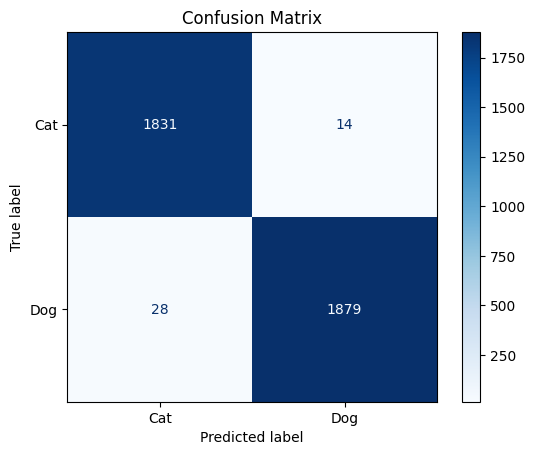

In [19]:
y_true = []
y_score = []

for images, rotulos in test_ds:
    probabilities = model_new.predict(images, verbose=0)

    y_true.extend(rotulos.numpy())
    y_score.extend(probabilities[:, 1])

y_true = np.array(y_true)
y_score = np.array(y_score)

y_pred = (y_score >= 0.5).astype(int)

matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["Cat", "Dog"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

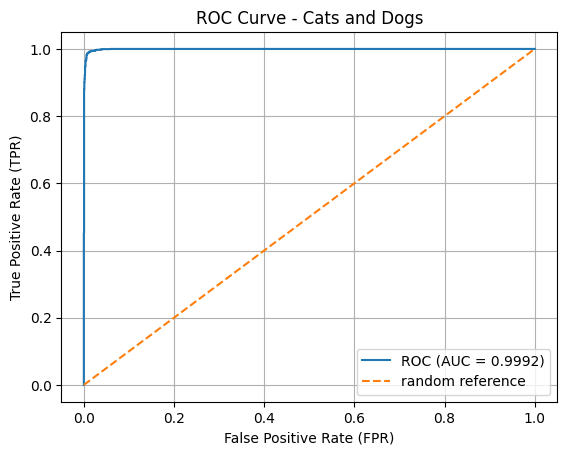

AUC: 0.9992


In [20]:
fpr, tpr, limiares = roc_curve(y_true, y_score)

auc = roc_auc_score(y_true, y_score)

plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="random reference")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve - Cats and Dogs")

plt.legend()
plt.grid(True)
plt.show()

print(f"AUC: {auc:.4f}")